# Affine transform - with label(bbox & keypoints)

전체 이미지를 affine transform 하고, 그 다음에 변형된 bbox, keypoint 좌표까지 구해내는 셋팅

transform matrix는 wikipedia에 있는 수식 참고
https://en.wikipedia.org/wiki/Affine_transformation#Image_transformation

변환 순서
1. xflip (좌우 플립)
2. resizing
3. rotating

rotating 하고 나서 원본 사이즈 넘어가는 부분 처리
- bbox: 원본 사이즈에 맞춰서 축소하는 방향으로 조정
- keypoints: 해당 키포인트를 버린다.

In [1]:
import torch

from torchvision.transforms.v2.functional import affine
from torchvision.transforms.v2 import InterpolationMode

In [48]:
image_path = '/home/dev/pose/data/coco/images/train2017/000000537548.jpg'

height = 480
width = 640
bbox = [267, 104, 229, 320]
kp = torch.tensor([[  0,   0,   0],
                   [  0,   0,   0],
                   [  0,   0,   0],
                   [  0,   0,   0],
                   [  0,   0,   0],
                   [325, 160,   2],
                   [398, 177,   2],
                   [  0,   0,   0],
                   [437, 238,   2],
                   [  0,   0,   0],
                   [477, 270,   2],
                   [287, 255,   1],
                   [339, 267,   2],
                   [  0,   0,   0],
                   [423, 314,   2],
                   [  0,   0,   0],
                   [355, 367,   2]], dtype=torch.int32)

In [49]:
%matplotlib inline
from matplotlib import pyplot as plt
from torchvision.io import read_image
from torchvision.transforms.v2 import ToPILImage

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

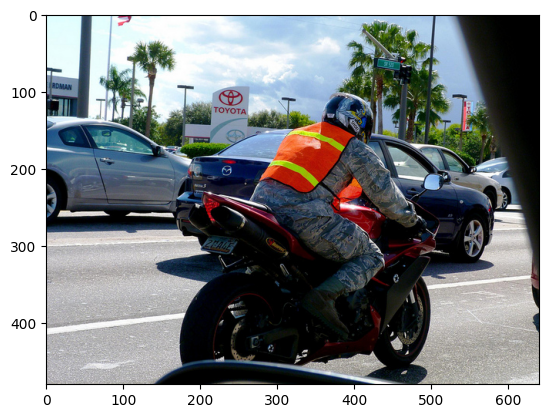

In [50]:
img = read_image(image_path)
plt_img = to_pil(img)

plt.imshow(plt_img)
plt.show()

# Bbox

https://pytorch.org/vision/main/generated/torchvision.utils.draw_bounding_boxes.html

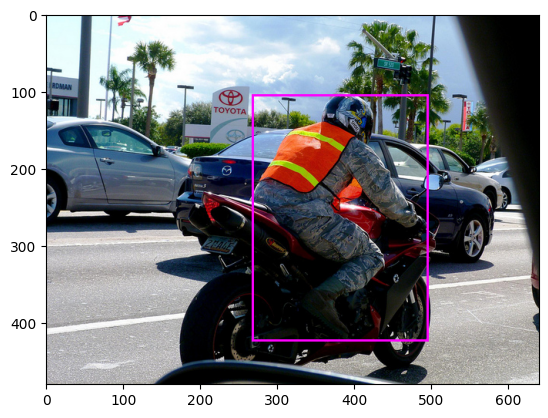

In [51]:
from torchvision.utils import draw_bounding_boxes

bbox_4p = torch.tensor([[bbox[0], bbox[1], bbox[0]+bbox[2], bbox[1]+bbox[3]]])

img = read_image(image_path)
img = draw_bounding_boxes(img, bbox_4p, colors=COLOR_MAGENTA, width=3)

img = to_pil(img)
plt.imshow(img)
plt.show()

### bbox - 회전

다시 보니까, 회전할 때 센터를 default(image center) 쓰면 안되고 bbox 센터를 써야겠다.

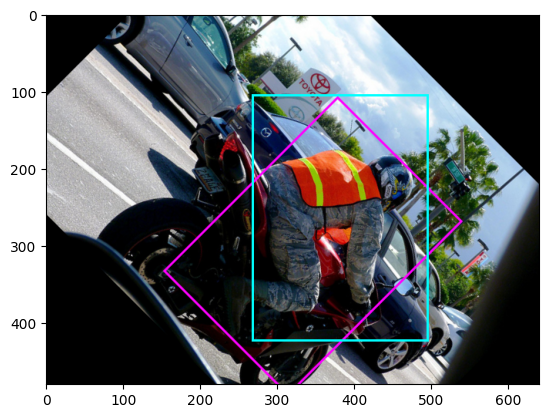

In [52]:
angle = 45          # angle in degree: -180 to 180
translate = [0, 0]  # horizontal and vertical translations
scale = 1.0         # overall scale
shear = [0, 0]
interpolation = InterpolationMode.BILINEAR
fill = None
center = None

img = read_image(image_path)
img = draw_bounding_boxes(img, bbox_4p, colors=COLOR_MAGENTA, width=3)   # original bbox (magenta)

img = affine(img, angle, translate, scale, shear, interpolation, fill, center)

tr_bbox_4p = bbox_4p
img = draw_bounding_boxes(img, tr_bbox_4p, colors=COLOR_CYAN, width=3)   # transformed bbox (cyan)

img = to_pil(img)
plt.imshow(img)
plt.show()

### bbox는 생각보다 난해하네 🤔🤔🤔

rotation하면 bbox를 다시 잡아야겠는데?

- 음.. 두 개 bbox 교점을 고려해서, 그 안을 bbox로 잡고, 그 안에 있는 keypoint로만 잘라버릴까?
- 아니면, crop을 하고 나서 rotating하고, 사진이 있는 영역과 padding을 넣게 되는 영역(=검정색 영역을 의미) 비중을 고려해서 가로로 컷팅한다든가 해야겠는걸

-> 이 아이디어가 일반화 가능하긴 할까? 위 사진은 인물이 가운데 있어서 그나마 되는거고, 안되는 케이스가 많을 것 같은데.

-> 그러면, 센터를 잘 잡아서 rotation 해야한다는 결론이 나온다. ✅ (그러면 그나마 bbox 잡는게 수월해질 것 같다.)

**keypoint 중에 max, min 값에 패딩 넣어주는 식으로 다시 잡아야겠다.**

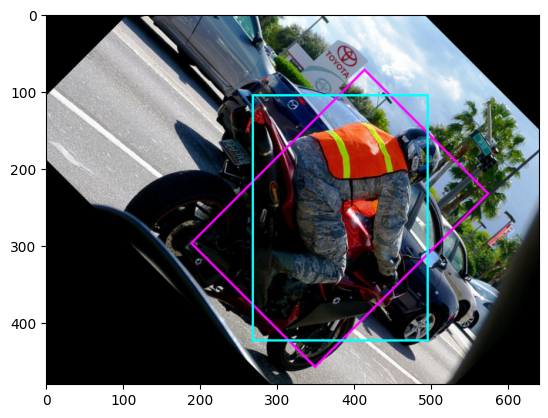

In [95]:
angle = 45          # angle in degree: -180 to 180
translate = [0, 0]  # horizontal and vertical translations
scale = 1.0         # overall scale
shear = [0, 0]
interpolation = InterpolationMode.BILINEAR
fill = None
center = [int(bbox[0] + bbox[2]/2), int(bbox[1] + bbox[3]/2)]

img = read_image(image_path)
img = draw_bounding_boxes(img, bbox_4p, colors=COLOR_MAGENTA, width=3)   # original bbox (magenta)

img = affine(img, angle, translate, scale, shear, interpolation, fill, center)

tr_bbox_4p = bbox_4p
img = draw_bounding_boxes(img, tr_bbox_4p, colors=COLOR_CYAN, width=3)   # transformed bbox (cyan)

img = to_pil(img)
plt.imshow(img)
plt.show()

# Keypoints

https://pytorch.org/vision/main/generated/torchvision.utils.draw_keypoints.html

In [53]:
kp

tensor([[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        [325, 160,   2],
        [398, 177,   2],
        [  0,   0,   0],
        [437, 238,   2],
        [  0,   0,   0],
        [477, 270,   2],
        [287, 255,   1],
        [339, 267,   2],
        [  0,   0,   0],
        [423, 314,   2],
        [  0,   0,   0],
        [355, 367,   2]], dtype=torch.int32)

In [54]:
kp.shape

torch.Size([17, 3])

In [55]:
kp[:,:2].reshape(1,17,2)

tensor([[[  0,   0],
         [  0,   0],
         [  0,   0],
         [  0,   0],
         [  0,   0],
         [325, 160],
         [398, 177],
         [  0,   0],
         [437, 238],
         [  0,   0],
         [477, 270],
         [287, 255],
         [339, 267],
         [  0,   0],
         [423, 314],
         [  0,   0],
         [355, 367]]], dtype=torch.int32)

In [56]:
kp_formatted = kp[:,:2].reshape(1,17,2)

In [57]:
visibility = kp[:,2].reshape(1,17)

In [62]:
connectivity = [[15, 13], [13, 11], [16, 14], [14, 12], [11, 12], [5, 11],
                          [6, 12], [5, 6], [5, 7], [6, 8], [7, 9], [8, 10], [1, 2],
                          [0, 1], [0, 2], [1, 3], [2, 4], [3, 5], [4, 6]]

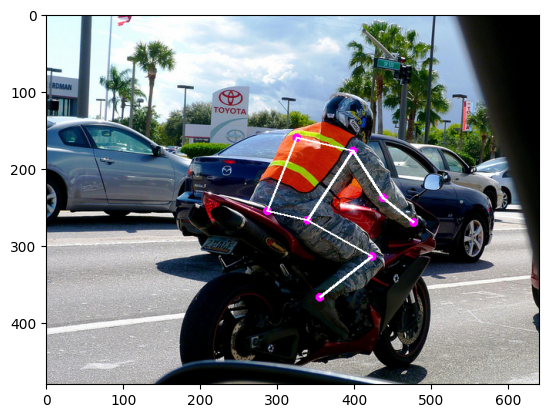

In [65]:
from torchvision.utils import draw_keypoints

img = read_image(image_path)
img = draw_keypoints(img, kp_formatted, connectivity=connectivity, colors=COLOR_MAGENTA, radius=5, visibility=visibility)

img = to_pil(img)
plt.imshow(img)
plt.show()

In [66]:
import math

In [67]:
kp[:,:2].float()

tensor([[  0.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [  0.,   0.],
        [325., 160.],
        [398., 177.],
        [  0.,   0.],
        [437., 238.],
        [  0.,   0.],
        [477., 270.],
        [287., 255.],
        [339., 267.],
        [  0.,   0.],
        [423., 314.],
        [  0.,   0.],
        [355., 367.]])

In [68]:
angle = -45
theta = math.pi * angle / 180
M = [[math.cos(theta), -1 * math.sin(theta)],
     [math.sin(theta), math.cos(theta)]]
M = torch.tensor(M)

kp_transformed = torch.matmul(kp[:,:2].float(), M).int()

In [70]:
theta

-0.7853981633974483

In [72]:
kp_transformed

tensor([[  0,   0],
        [  0,   0],
        [  0,   0],
        [  0,   0],
        [  0,   0],
        [116, 342],
        [156, 406],
        [  0,   0],
        [140, 477],
        [  0,   0],
        [146, 528],
        [ 22, 383],
        [ 50, 428],
        [  0,   0],
        [ 77, 521],
        [  0,   0],
        [ -8, 510]], dtype=torch.int32)

### 로테이션 이전 이후 비교

affine rotation은 image center rotation

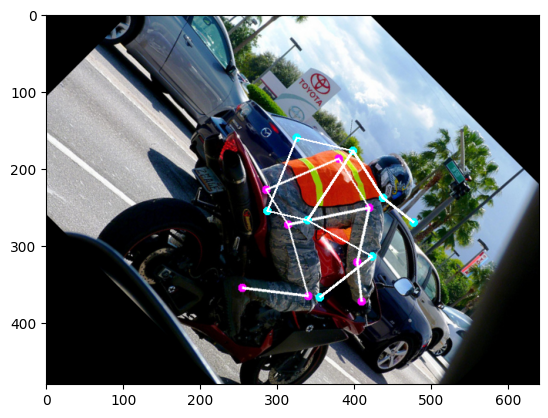

In [73]:
angle = 45          # angle in degree: -180 to 180
translate = [0, 0]  # horizontal and vertical translations
scale = 1.0         # overall scale
shear = [0, 0]
interpolation = InterpolationMode.BILINEAR
fill = None
center = None

img = read_image(image_path)
img = img = draw_keypoints(img, kp_formatted, connectivity=connectivity, colors=COLOR_MAGENTA, radius=5, visibility=visibility)   # original keypoints (magenta)

img = affine(img, angle, translate, scale, shear, interpolation, fill, center)
img = draw_keypoints(img, kp_formatted, connectivity=connectivity, colors=COLOR_CYAN, radius=5, visibility=visibility)   # transformed keypoints (cyan)

img = to_pil(img)
plt.imshow(img)
plt.show()

torch affine 에서 rotation은 default은 이미지 센터인데, 내가 keypoint 전환할때 origin(upper left corner)으로 -45도 돌려버려서 저렇게 내려갔다.

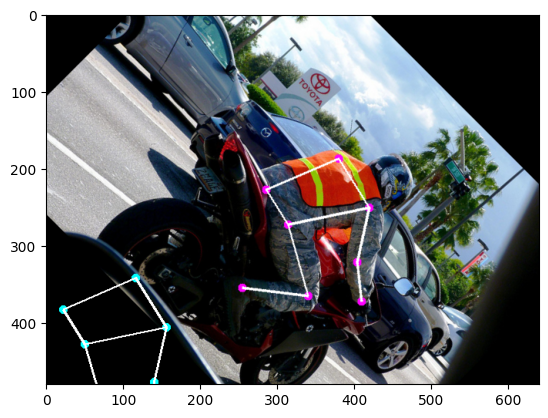

In [74]:
angle = 45          # angle in degree: -180 to 180
translate = [0, 0]  # horizontal and vertical translations
scale = 1.0         # overall scale
shear = [0, 0]
interpolation = InterpolationMode.BILINEAR
fill = None
center = None

img = read_image(image_path)
img = img = draw_keypoints(img, kp_formatted, connectivity=connectivity, colors=COLOR_MAGENTA, radius=5, visibility=visibility)   # original keypoints (magenta)

img = affine(img, angle, translate, scale, shear, interpolation, fill, center)
img = img = draw_keypoints(img, kp_transformed.reshape(1,17,2), connectivity=connectivity, colors=COLOR_CYAN, radius=5, visibility=visibility)   # transformed keypoints (cyan)

img = to_pil(img)
plt.imshow(img)
plt.show()

## Image center -> bbox center rotation

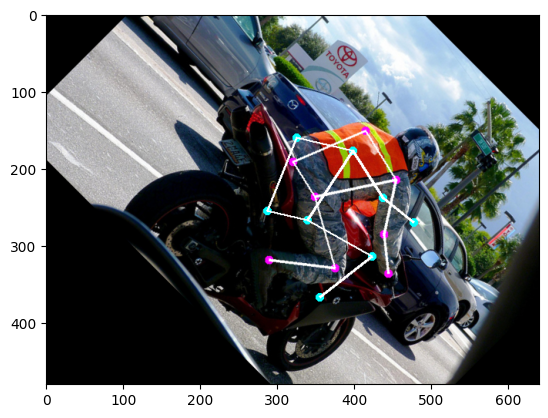

In [75]:
angle = 45          # angle in degree: -180 to 180
translate = [0, 0]  # horizontal and vertical translations
scale = 1.0         # overall scale
shear = [0, 0]
interpolation = InterpolationMode.BILINEAR
fill = None
center = [int(bbox[0] + bbox[2]/2), int(bbox[1] + bbox[3]/2)]

img = read_image(image_path)
img = img = draw_keypoints(img, kp_formatted, connectivity=connectivity, colors=COLOR_MAGENTA, radius=5, visibility=visibility)   # original keypoints (magenta)

img = affine(img, angle, translate, scale, shear, interpolation, fill, center)
img = img = draw_keypoints(img, kp_formatted, connectivity=connectivity, colors=COLOR_CYAN, radius=5, visibility=visibility)   # transformed keypoints (cyan)

img = to_pil(img)
plt.imshow(img)
plt.show()

In [77]:
bbox_center = torch.tensor([int(bbox[0] + bbox[2]/2), int(bbox[1] + bbox[3]/2)])

In [91]:
angle = 60
theta = -1 * math.pi * angle / 180
M = [[math.cos(theta), -1 * math.sin(theta)],
     [math.sin(theta), math.cos(theta)]]
M = torch.tensor(M)

kp_transformed = torch.matmul((kp[:,:2] - bbox_center).float(), M).int() + bbox_center

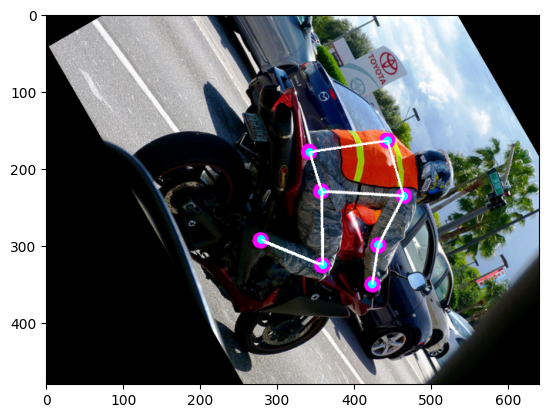

In [93]:
angle = 60          # angle in degree: -180 to 180
translate = [0, 0]  # horizontal and vertical translations
scale = 1.0         # overall scale
shear = [0, 0]
interpolation = InterpolationMode.BILINEAR
fill = None
center = [int(bbox[0] + bbox[2]/2), int(bbox[1] + bbox[3]/2)]

img = read_image(image_path)
img = img = draw_keypoints(img, kp_formatted, connectivity=connectivity, colors=COLOR_MAGENTA, radius=10, visibility=visibility)   # original keypoints (magenta)

img = affine(img, angle, translate, scale, shear, interpolation, fill, center)
img = img = draw_keypoints(img, kp_transformed.reshape(1,17,2), connectivity=connectivity, colors=COLOR_CYAN, radius=5, visibility=visibility)   # transformed keypoints (cyan)

img = to_pil(img)
plt.imshow(img)
plt.show()